In [127]:
import os

# Convert the raw UCI .txt (';'-separated, '?' = missing) to CSV once
if not os.path.exists('household_power_consumption.csv'):
    with open('household_power_consumption.txt', newline='') as src, open('household_power_consumption.csv', 'w', newline='') as dst:
        for line in src:
            dst.write(line.replace(';', ',').replace('?', ''))

In [128]:
import os, sys
os.environ['PATH'] = os.path.join(sys.prefix, 'Library', 'bin') + os.pathsep + os.environ.get('PATH', '')
import torch
print(sys.executable)
print(torch.backends.cudnn.version())

c:\Users\ahaze\anaconda3\envs\4010-DeepLearning\python.exe
92800


In [129]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('household_power_consumption.csv')
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).set_index('Datetime')
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


### GPU check
Confirms which device PyTorch will train on. Every model below is moved to `device`.

In [130]:
import os
import random
import sys
import numpy as np

os.environ['PATH'] = os.path.join(sys.prefix, 'Library', 'bin') + os.pathsep + os.environ.get('PATH', '')
import torch

print('PyTorch', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('CUDA version:', torch.version.cuda, '| cuDNN version:', torch.backends.cudnn.version())

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    print('Training on GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU found, training on CPU')

# A small matmul proves tensors actually land on the chosen device
probe = torch.randn(256, 256, device=device)
print('Test matmul ran on:', (probe @ probe).device)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # also seeds CUDA

# Deterministic cuDNN kernels so GPU runs repeat exactly with the same seed
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
set_seed()

PyTorch 2.14.1
CUDA available: True
CUDA version: 13.4 | cuDNN version: 92800
Training on GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Test matmul ran on: cuda:0


## Basic investigation

In [131]:
print('Shape:', df.shape)
print('Range:', df.index.min(), '->', df.index.max())
print('Timestamps unique and evenly spaced (1 min):', df.index.is_unique and (df.index.to_series().diff().dropna() == pd.Timedelta('1min')).all())
df.info()

Shape: (2075259, 7)
Range: 2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Timestamps unique and evenly spaced (1 min): True
<class 'pandas.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB


In [132]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049280.0,1.091615,1.057294,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049280.0,0.123714,0.112722,0.000,0.048,0.100,0.194,1.390
Voltage,2049280.0,240.839858,3.239987,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049280.0,4.627759,4.444396,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049280.0,1.121923,6.153031,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049280.0,1.298520,5.822026,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049280.0,6.458447,8.437154,0.000,0.000,1.000,17.000,31.000


### Missing values

In [133]:
missing = df.isna()
print('Missing per column:')
print(missing.sum())
print(f'\nRows with any missing: {missing.any(axis=1).sum()} ({missing.any(axis=1).mean():.2%})')

# Missing values come in contiguous gaps; list the longest ones
row_missing = missing.any(axis=1)
gap_id = (row_missing != row_missing.shift()).cumsum()
gaps = row_missing[row_missing].groupby(gap_id[row_missing]).agg(
    start=lambda s: s.index.min(), end=lambda s: s.index.max(), minutes='size')
print(f'\nNumber of gaps: {len(gaps)}')
gaps.sort_values('minutes', ascending=False).head(10).reset_index(drop=True)

Missing per column:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Rows with any missing: 25979 (1.25%)

Number of gaps: 71


,start,end,minutes
0,2010-08-17 21:02:00,2010-08-22 21:27:00,7226
1,2010-09-25 03:56:00,2010-09-28 19:12:00,5237
2,2007-04-28 00:21:00,2007-04-30 14:23:00,3723
3,2009-06-13 00:30:00,2009-06-15 07:34:00,3305
4,2010-01-12 14:53:00,2010-01-14 19:01:00,3129
5,2010-03-20 03:52:00,2010-03-21 13:38:00,2027
6,2009-08-13 05:00:00,2009-08-13 19:50:00,891
7,2007-07-15 16:49:00,2007-07-15 18:11:00,83
8,2008-12-10 10:48:00,2008-12-10 11:57:00,70
9,2007-07-15 18:21:00,2007-07-15 19:07:00,47


### Distributions

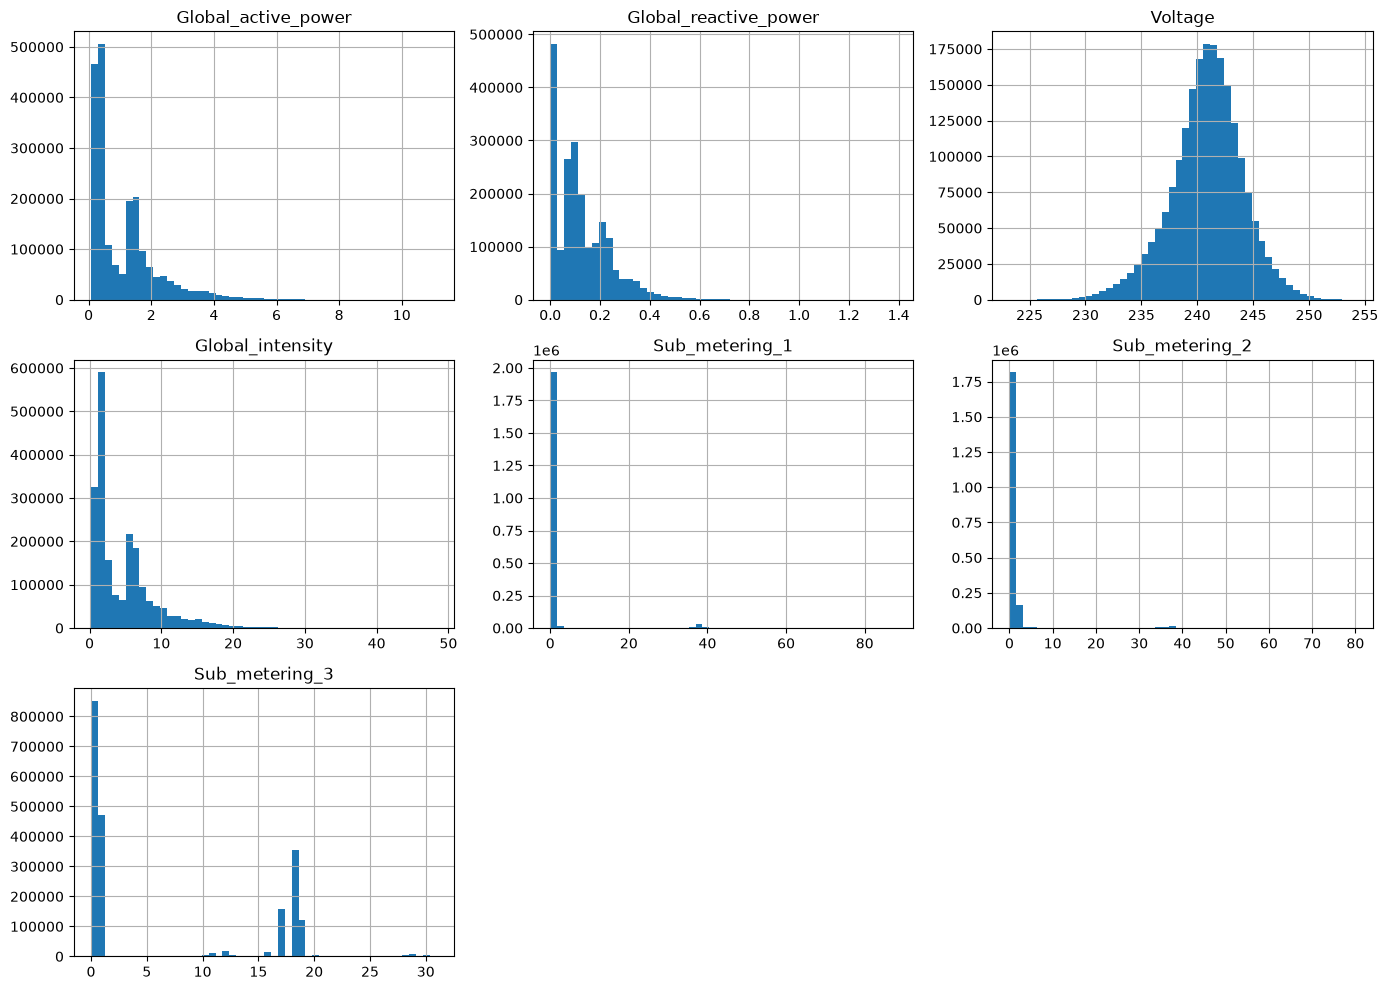

In [134]:
df.hist(bins=50, figsize=(14, 10))
plt.tight_layout()
plt.show()

### Correlations

In [135]:
df.corr().round(2)

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Global_active_power,1.00,0.25,-0.40,1.00,0.48,0.43,0.64
Global_reactive_power,0.25,1.00,-0.11,0.27,0.12,0.14,0.09
Voltage,-0.40,-0.11,1.00,-0.41,-0.20,-0.17,-0.27
Global_intensity,1.00,0.27,-0.41,1.00,0.49,0.44,0.63
Sub_metering_1,0.48,0.12,-0.20,0.49,1.00,0.05,0.10
Sub_metering_2,0.43,0.14,-0.17,0.44,0.05,1.00,0.08
Sub_metering_3,0.64,0.09,-0.27,0.63,0.10,0.08,1.00


### Trends and seasonality

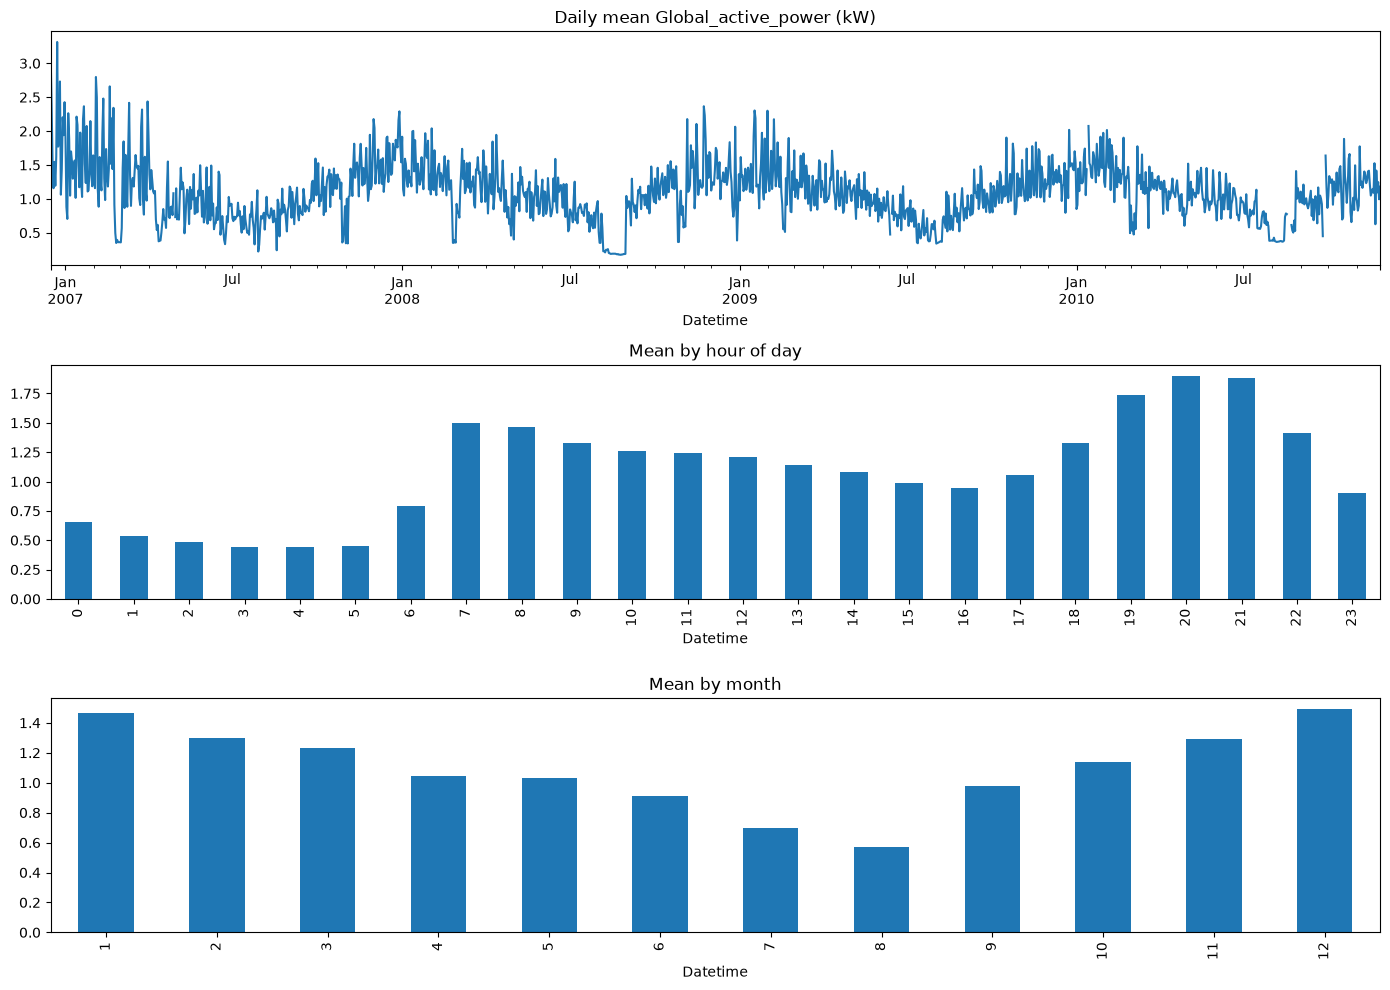

In [136]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
df['Global_active_power'].resample('D').mean().plot(ax=axes[0], title='Daily mean Global_active_power (kW)')
df['Global_active_power'].groupby(df.index.hour).mean().plot(ax=axes[1], kind='bar', title='Mean by hour of day')
df['Global_active_power'].groupby(df.index.month).mean().plot(ax=axes[2], kind='bar', title='Mean by month')
plt.tight_layout()
plt.show()

## Problem definition and data audit

| | |
|---|---|
| **Source** | UCI Individual Household Electric Power Consumption (#235), CC BY 4.0 |
| **Target** | `Global_active_power` (GAP), kW: the whole-house real power draw |
| **Native frequency** | 1 minute |
| **Resampling rule** | Hourly mean (an hour needs at least 30 recorded minutes, otherwise it counts as missing) |
| **Lookback / horizon** | 168 h (one week) in, next 24 h out |
| **Inputs** | Past 168 h of measured columns kept by the ablation (lagged only; `Global_intensity` is always dropped), causal 7-day / 28-day load levels, same-calendar-time last-year load, calendar phase, and the seasonal residual if one is used |

**Operational meaning:** at hour *t* we forecast the household's load profile for the next day, using only data observed before *t*. That is the setting for day-ahead load planning and demand response.

In [137]:
TARGET = 'Global_active_power'
LOOKBACK, HORIZON = 168, 24
DAY, WEEK = 24, 168  # seasonal periods in hours

audit = pd.Series({
    'Target': f'{TARGET} (kW)',
    'Coverage': f'{df.index.min()} -> {df.index.max()}',
    'Rows (1 min)': len(df),
    'Duplicate timestamps': df.index.duplicated().sum(),
    'Missing rows': f'{row_missing.sum()} ({row_missing.mean():.2%})',
    'Missing gaps': len(gaps),
    'Longest gap': f"{gaps['minutes'].max() / 60 / 24:.1f} days",
    'Lookback / horizon': f'{LOOKBACK} h / {HORIZON} h',
}, name='Value')
audit.to_frame()

,Value
Target,Global_active_power (kW)
Coverage,2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Rows (1 min),2075259
Duplicate timestamps,0
Missing rows,25979 (1.25%)
Missing gaps,71
Longest gap,5.0 days
Lookback / horizon,168 h / 24 h


## Resampling and imputation
* **Resample:** hourly mean. Hours with fewer than 30 recorded minutes are set to missing.
* **Short gaps (≤ 3 h):** forward fill, which carries the last observed hour forward.
* **Long gaps (up to about 5 days):** the value from the same hour one week earlier. Any remainder is forward-filled.

Every fill is **causal**: a missing hour is filled only from earlier hours. Interpolation would use the next observed hour, which could be a target hour of the same window. Nothing here is fitted to data either, so imputation cannot leak test statistics into training. The `imputed` mask is kept so we can report how much of each split is filled in.

In [138]:
counts = df[TARGET].resample('h').count()
hourly_raw = df.resample('h').mean()
hourly_raw.loc[counts < 30] = np.nan
imputed = hourly_raw[TARGET].isna()

# Length of each run of missing hours
run_id = (imputed != imputed.shift()).cumsum()
run_len = imputed.groupby(run_id).transform('size')
short_gap = imputed & (run_len <= 3)

hourly = hourly_raw.copy()
hourly.loc[short_gap] = hourly_raw.ffill().loc[short_gap]
for _ in range(2):  # a second pass covers gaps whose previous week was also missing
    hourly = hourly.fillna(hourly.shift(WEEK))
hourly = hourly.ffill().dropna()  # only leading hours with no history can remain; drop them
imputed = imputed.loc[hourly.index]

assert not hourly.isna().any().any()
print(f'Hourly rows: {len(hourly)} | imputed hours: {imputed.sum()} ({imputed.mean():.2%}), '
      f'of which short gaps: {short_gap.sum()}')

Hourly rows: 34589 | imputed hours: 432 (1.25%), of which short gaps: 7


## Why GAP is the target, and why the other measurements must be lagged
The charts below use the hourly data **before imputation**, so filled-in values can't create artificial correlation.

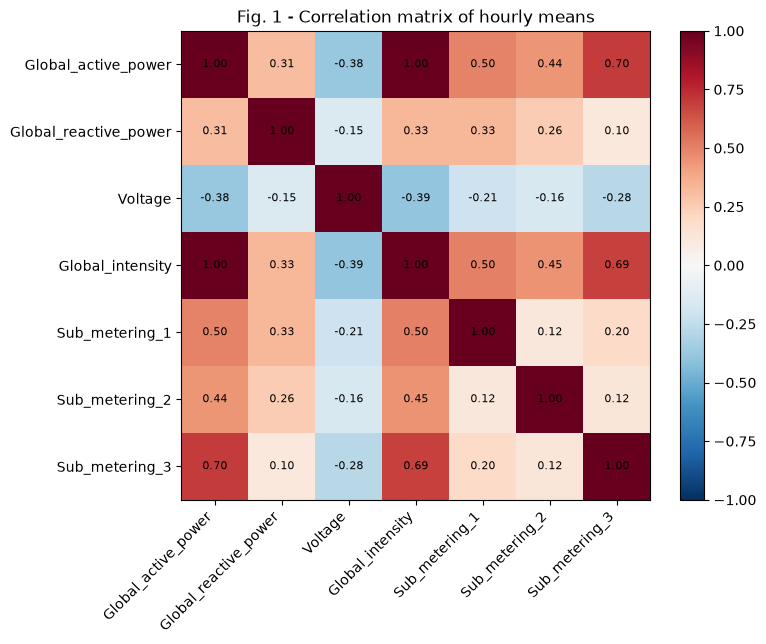

In [139]:
corr = hourly_raw.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title('Fig. 1 - Correlation matrix of hourly means')
plt.tight_layout()
plt.show()

Sub-meters cover on average 38% of GAP


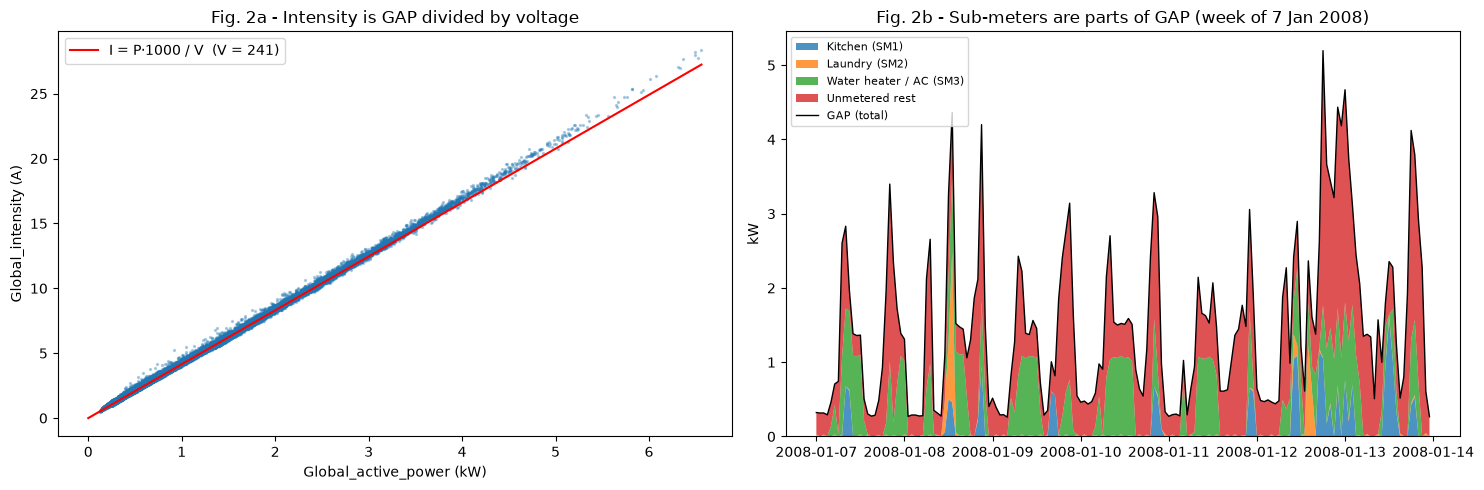

In [140]:
h = hourly_raw.dropna()
sub_cols = ['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

def sub_kw(frame):
    return frame[sub_cols] * 60 / 1000  # sub-meters are Wh per minute -> kW

print(f'Sub-meters cover on average {(sub_kw(h).sum(axis=1) / h[TARGET]).mean():.0%} of GAP')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

v = h['Voltage'].mean()
axes[0].scatter(h[TARGET], h['Global_intensity'], s=2, alpha=0.3)
x = np.linspace(0, h[TARGET].max(), 100)
axes[0].plot(x, x * 1000 / v, 'r', label=f'I = P·1000 / V  (V = {v:.0f})')
axes[0].set(xlabel='Global_active_power (kW)', ylabel='Global_intensity (A)',
            title='Fig. 2a - Intensity is GAP divided by voltage')
axes[0].legend()

week = hourly_raw.loc['2008-01-07':'2008-01-13']
parts = sub_kw(week)
parts.columns = ['Kitchen (SM1)', 'Laundry (SM2)', 'Water heater / AC (SM3)']
parts['Unmetered rest'] = week[TARGET] - parts.sum(axis=1)
axes[1].stackplot(parts.index, parts.T, labels=parts.columns, alpha=0.8)
axes[1].plot(week.index, week[TARGET], 'k', lw=1, label='GAP (total)')
axes[1].set(ylabel='kW', title='Fig. 2b - Sub-meters are parts of GAP (week of 7 Jan 2008)')
axes[1].legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

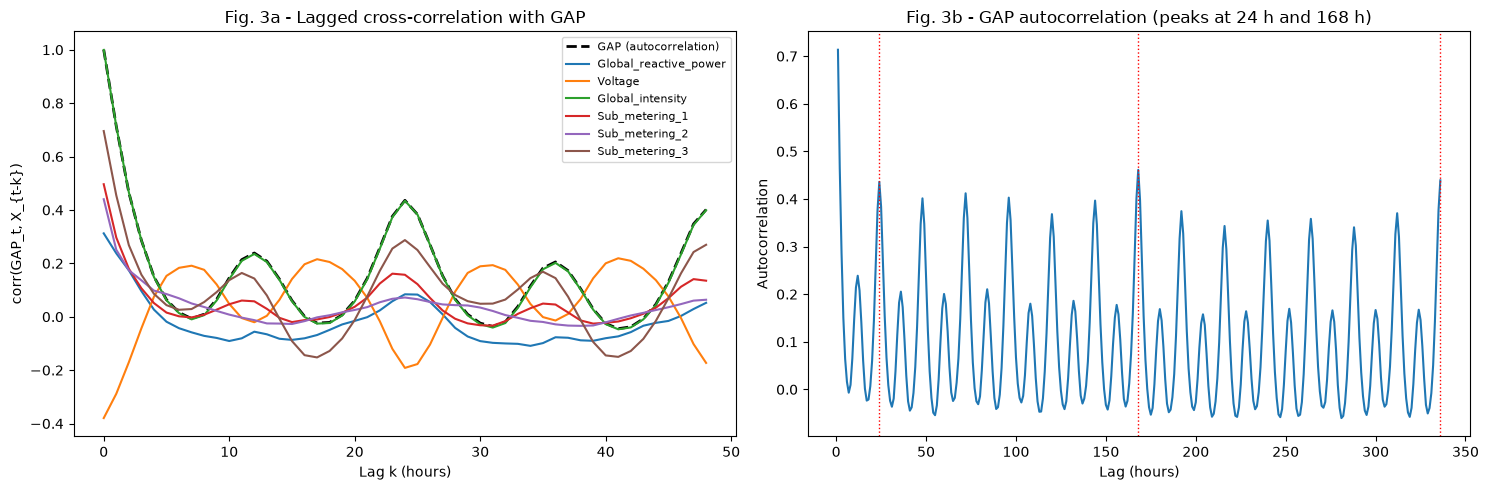

,lag 0 h,lag 1 h,lag 24 h,lag 48 h
Global_active_power,1.00,0.71,0.44,0.40
Global_reactive_power,0.31,0.24,0.08,0.05
Voltage,-0.38,-0.29,-0.19,-0.17
Global_intensity,1.00,0.71,0.43,0.40
Sub_metering_1,0.50,0.30,0.16,0.14
Sub_metering_2,0.44,0.25,0.07,0.06
Sub_metering_3,0.70,0.45,0.29,0.27


In [141]:
lags = range(49)
xcorr = pd.DataFrame({col: [hourly_raw[TARGET].corr(hourly_raw[col].shift(k)) for k in lags]
                      for col in hourly_raw.columns}, index=lags)
acf_lags = range(1, 2 * WEEK + 1)
acf = pd.Series([hourly_raw[TARGET].autocorr(k) for k in acf_lags], index=acf_lags)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for col in xcorr.columns:
    style = dict(color='k', ls='--', lw=2) if col == TARGET else {}
    label = 'GAP (autocorrelation)' if col == TARGET else col
    axes[0].plot(xcorr.index, xcorr[col], label=label, **style)
axes[0].set(xlabel='Lag k (hours)', ylabel='corr(GAP_t, X_{t-k})',
            title='Fig. 3a - Lagged cross-correlation with GAP')
axes[0].legend(fontsize=8)

axes[1].plot(acf.index, acf)
for k in (DAY, WEEK, 2 * WEEK):
    axes[1].axvline(k, color='r', ls=':', lw=1)
axes[1].set(xlabel='Lag (hours)', ylabel='Autocorrelation',
            title='Fig. 3b - GAP autocorrelation (peaks at 24 h and 168 h)')

plt.tight_layout()
plt.show()

xcorr.loc[[0, 1, 24, 48]].T.round(2).rename(columns=lambda k: f'lag {k} h')

**Why GAP is the target**
* GAP is the total real power the household draws, which is what the meter bills. That makes forecasting it directly useful.
* `Global_intensity` is the same quantity in amps (Fig. 1 r ≈ 1.00, Fig. 2a: it lies on I = P·1000/V). Forecasting it would be the same task in different units.
* The sub-meters only cover some circuits (Fig. 2b). A large "unmetered" share remains, so none of them describes the whole house.
* `Voltage` mostly reflects the grid, and `Global_reactive_power` isn't billed. Neither describes household consumption.

**Why the other measurements are lagged inputs only**
* At lag 0, `Global_intensity` is almost perfectly correlated with GAP (Fig. 3a). Feeding the same-hour value into the model would leak the answer: the "forecast" would just be a unit conversion. We wouldn't have that value at forecast time anyway.
* Once lagged (k ≥ 1), every feature's correlation falls to roughly GAP's own autocorrelation level or below. They add context (for example, which appliances were recently on) without revealing the target. This is the spec §3 rule: contemporaneous measurements may only be used as lagged inputs.
* The autocorrelation peaks at 24 h and 168 h (Fig. 3b) show daily and weekly cycles. The model also gets causal rolling load levels, annual phase, and same-calendar-time last-year load to represent slower changes.

## Chronological split (60 / 20 / 20) and windows
* The split is by time, never shuffled globally. The scaler is **fit on training rows only**.
* Each window holds 168 hours of inputs (`t-168 … t-1`) and the 24 target hours `t … t+23`.
* Windows are still created hourly for training, but model selection also reports and optimizes the operational **midnight-origin, one-forecast-per-day** score.
* For validation and test windows, the lookback may reach back into the previous split. That is past data, so it's allowed, but **targets always stay inside their own split**.
* The splits cover different seasons: train has three full winters, while test (Feb to Nov 2010) is mostly the low-load months. Absolute MAE is therefore not comparable across splits, so models are only ever compared on the same split.

In [142]:
features = hourly.copy()
idx = features.index
dow = idx.day_of_week.to_numpy()
year_phase = 2 * np.pi * ((idx.day_of_year.to_numpy() - 1) + idx.hour.to_numpy() / 24) / 365.2425
features['hour_sin'] = np.sin(2 * np.pi * idx.hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * idx.hour / 24)
features['dow_sin'] = np.sin(2 * np.pi * dow / 7)
features['dow_cos'] = np.cos(2 * np.pi * dow / 7)
features['is_weekend'] = (dow >= 5).astype(float)
for harmonic in (1, 2):
    features[f'year_sin_{harmonic}'] = np.sin(harmonic * year_phase)
    features[f'year_cos_{harmonic}'] = np.cos(harmonic * year_phase)

past_gap = hourly[TARGET]
causal_mean = past_gap.shift(1).expanding(min_periods=1).mean().fillna(past_gap.iloc[0])
annual_index = idx - pd.DateOffset(years=1)
annual_lag = past_gap.reindex(annual_index).to_numpy()
features['GAP_lag_1y_available'] = np.isfinite(annual_lag).astype(float)
features['GAP_lag_1y'] = np.where(np.isfinite(annual_lag), annual_lag, causal_mean.to_numpy())
for days in (7, 28):
    trailing = past_gap.shift(1).rolling(days * 24, min_periods=24).mean()
    features[f'GAP_mean_{days}d'] = trailing.fillna(causal_mean)
FEATURES = list(features.columns)
TARGET_IDX = FEATURES.index(TARGET)

n = len(features)
train_end, val_end = int(n * 0.6), int(n * 0.8)
splits = {'train': (0, train_end), 'val': (train_end, val_end), 'test': (val_end, n)}

pd.DataFrame([{'split': s, 'start': features.index[a], 'end': features.index[b - 1], 'hours': b - a,
               'imputed %': round(imputed.iloc[a:b].mean() * 100, 2)}
              for s, (a, b) in splits.items()]).set_index('split')

,start,end,hours,imputed %
split,,,,
train,2006-12-16 17:00:00,2009-04-29 09:00:00,20753,0.33
val,2009-04-29 10:00:00,2010-02-11 15:00:00,6918,1.76
test,2010-02-11 16:00:00,2010-11-26 21:00:00,6918,3.50


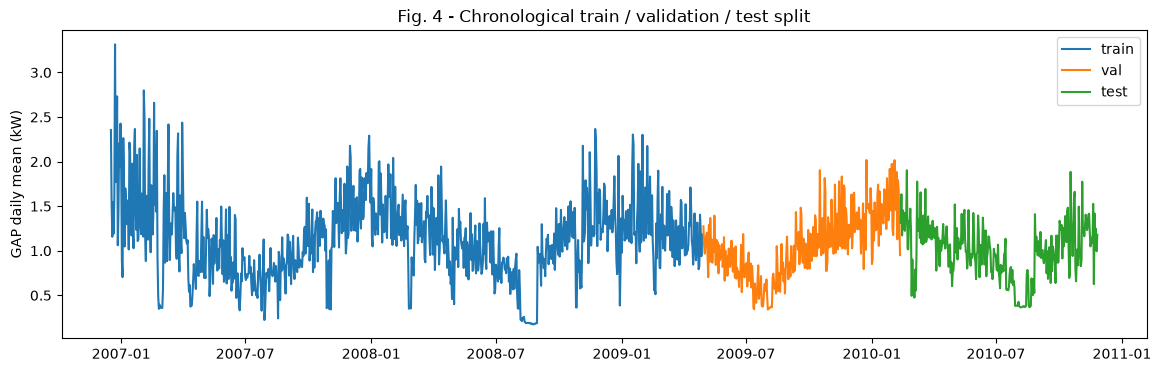

In [143]:
fig, ax = plt.subplots(figsize=(14, 4))
daily = features[TARGET].resample('D').mean()
for s, (a, b) in splits.items():
    part = daily.loc[features.index[a]:features.index[b - 1]]
    ax.plot(part.index, part, label=s)
ax.set(ylabel='GAP daily mean (kW)', title='Fig. 4 - Chronological train / validation / test split')
ax.legend()
plt.show()

## Causal seasonal decomposition (stationarity)
GAP has strong daily and weekly cycles and a level that shifts with the season (Fig. 4). Instead of forecasting GAP directly, a model can forecast the **residual** around a seasonal baseline `B`, and `B` is added back afterwards. Classical decompositions (STL, `seasonal_decompose`) use a *centred* moving average, which looks at future hours, so they would leak the target. Both baselines here are causal:
* **week:** `B[t] = GAP[t-168]` (seasonal differencing). For every target hour `t+h` (`h < 24`) that value is already inside the 168-h lookback.
* **profile:** the mean GAP for each of the 168 hours of the week, **fitted on training rows only** (the same rule as the scaler). It depends only on the calendar, which is known in advance.
* **profile_year:** the weekly profile plus a month-of-year level adjustment, both estimated from training rows only. Months not present in training use no annual adjustment. This gives a simple annual-seasonal forecast without using future measurements.

The feature windows also include annual Fourier calendar terms, a same-calendar-time last-year load (with an availability flag), and trailing 7-day / 28-day means. Rolling statistics and annual lags are strictly past-only; missing early annual lags fall back to a causal expanding mean.
* **none:** `B = 0`, i.e. the original target.

Fig. 5 shows the 30-day rolling mean and std on the training rows. A flatter curve means a more stationary series. The ablation in the baselines section picks the variant on validation.

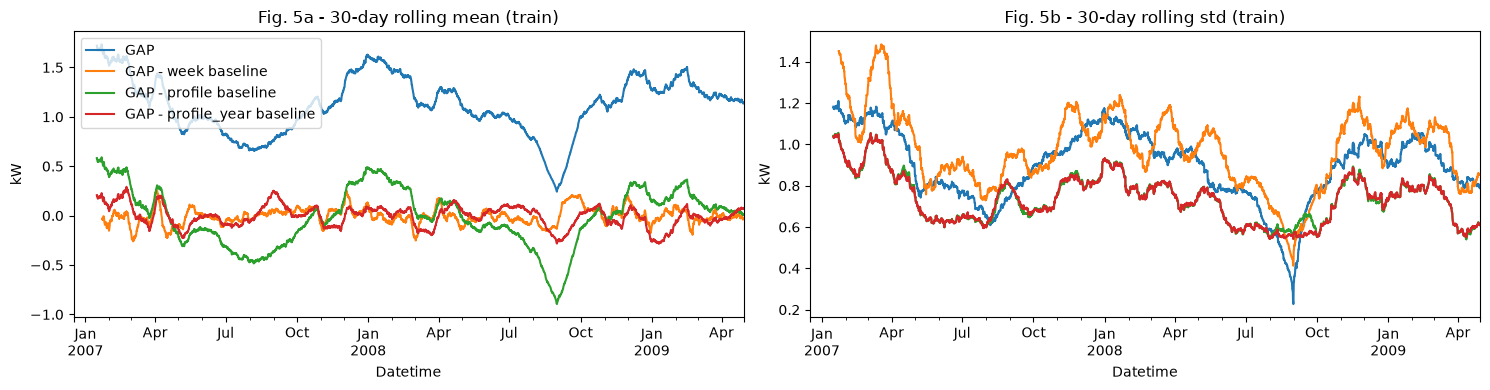

In [144]:
gap = hourly[TARGET].to_numpy()
how = (features.index.day_of_week * 24 + features.index.hour).to_numpy()  # hour of the week, 0-167
profile = pd.Series(gap[:train_end]).groupby(how[:train_end]).mean()  # train rows only
weekly_profile = profile.reindex(how).to_numpy()
train_residual = gap[:train_end] - weekly_profile[:train_end]
month_effect = pd.Series(train_residual).groupby(features.index.month[:train_end]).mean()
annual_adjustment = pd.Series(features.index.month).map(month_effect).fillna(0.0).to_numpy()
annual_profile = weekly_profile + annual_adjustment
seasonal_base = {
    'none': np.zeros(n),
    'week': np.r_[np.full(WEEK, np.nan), gap[:-WEEK]],  # same hour one week earlier
    'profile': weekly_profile,
    'profile_year': annual_profile,
}

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for variant, b in seasonal_base.items():
    resid = pd.Series(gap[:train_end] - b[:train_end], index=features.index[:train_end])
    label = 'GAP' if variant == 'none' else f'GAP - {variant} baseline'
    resid.rolling(30 * DAY).mean().plot(ax=axes[0], label=label)
    resid.rolling(30 * DAY).std().plot(ax=axes[1], label=label)
axes[0].set(ylabel='kW', title='Fig. 5a - 30-day rolling mean (train)')
axes[1].set(ylabel='kW', title='Fig. 5b - 30-day rolling std (train)')
axes[0].legend()
plt.tight_layout()
plt.show()

In [145]:
from sklearn.preprocessing import StandardScaler

def to_kw(y, split):
    """Undo the target scaling and add the seasonal baseline back, so all metrics are in kW."""
    return y * x_scaler.scale_[TARGET_IDX] + x_scaler.mean_[TARGET_IDX] + base[split]

def make_windows(start, end):
    """Windows whose 24-h target lies in rows [start, end); the lookback may come from earlier rows."""
    # The 'week' residual needs one extra week of history; every variant uses the same windows so they compare fairly
    t = np.arange(max(start, LOOKBACK + WEEK), end - HORIZON + 1)
    X = np.stack([X_all[i - LOOKBACK:i] for i in t])
    y = np.stack([X_all[i:i + HORIZON, TARGET_IDX] for i in t])
    return X, y, t

def prepare(variant, drop):
    """Scale the inputs and build the windows for one seasonal baseline and column set (sets the globals used below)."""
    global FEATURES, TARGET_IDX, x_scaler, X_all, data, base, measured, daily_origin, Y_kw, X_train, y_train, X_val, y_val
    frame = features.drop(columns=drop)
    target_col = TARGET
    if variant != 'none':
        frame['GAP_resid'] = gap - seasonal_base[variant]  # raw GAP stays as a lagged input
        target_col = 'GAP_resid'
    FEATURES = list(frame.columns)
    TARGET_IDX = FEATURES.index(target_col)
    x_scaler = StandardScaler().fit(frame.iloc[:train_end])  # train rows only; NaNs (first week of 'week') are ignored
    X_all = x_scaler.transform(frame).astype(np.float32)

    data = {s: make_windows(a, b) for s, (a, b) in splits.items()}
    hours = {s: t[:, None] + np.arange(HORIZON) for s, (_, _, t) in data.items()}  # row index of every target hour
    base = {s: seasonal_base[variant][h] for s, h in hours.items()}
    measured = {s: ~imputed.to_numpy()[h] for s, h in hours.items()}
    daily_origin = {s: features.index[t].hour.to_numpy() == 0 for s, (_, _, t) in data.items()}
    Y_kw = {s: to_kw(y, s) for s, (_, y, _) in data.items()}

    X_train, y_train, t_train = data['train']
    X_val, y_val, t_val = data['val']
    assert X_train.shape[1:] == (LOOKBACK, len(FEATURES)) and y_train.shape[1] == HORIZON
    assert t_train[-1] + HORIZON <= train_end and t_val[-1] + HORIZON <= val_end  # no target crosses a split
    assert all(np.isfinite(X).all() for X, _, _ in data.values())
    for s, h in hours.items():  # adding the baseline back recovers the actual kW
        assert np.allclose(Y_kw[s], gap[h], atol=1e-3)

prepare('none', ['Global_intensity'])
for s, (X, y, t) in data.items():
    print(f'{s:5s}  X {X.shape}  y {y.shape}  targets {features.index[t[0]]} -> {features.index[t[-1] + HORIZON - 1]}')

train  X (20394, 168, 19)  y (20394, 24)  targets 2006-12-30 17:00:00 -> 2009-04-29 09:00:00
val    X (6895, 168, 19)  y (6895, 24)  targets 2009-04-29 10:00:00 -> 2010-02-11 15:00:00
test   X (6895, 168, 19)  y (6895, 24)  targets 2010-02-11 16:00:00 -> 2010-11-26 21:00:00


## Baselines (non-neural) and ablation
All models make the same 24-hour forecast from the same windows. Scores include the original rolling hourly forecast origins and a separate **midnight day-ahead** score, matching one forecast per day. MAE and RMSE use measured target hours only: long gaps are imputed with last week's values, which the week-naive baseline would "forecast" perfectly. MAE including imputed hours is kept as an extra column.
* **Seasonal naive (day):** the last 24 hours repeat.
* **Seasonal naive (week):** the same 24 hours one week earlier repeat.
* **Ridge regression** on the flattened 168 × F window. Alpha is chosen on validation.
* **Gradient boosting:** one `HistGradientBoostingRegressor` per forecast hour, on a compact summary of the window (the last 24 h of the target, the matching 24 h one week earlier, the 24-h and 168-h means, and the latest value of every input). Learning rate and leaf count are chosen on validation.

**Ablation (Ridge, validation):** every combination of seasonal baseline (none / week / profile / profile plus annual level) and column set is scored with Ridge on midnight origins. All models from here on use the winning combination.

Only validation scores are shown. The test set stays untouched.

In [146]:
import time
import warnings
from scipy.linalg import LinAlgWarning
from sklearn.linear_model import Ridge

warnings.filterwarnings('ignore', category=LinAlgWarning)  # the flattened window is collinear; the alpha search handles it

def evaluate(y_true, y_pred, mask=None):
    err = y_pred - y_true
    if mask is not None:
        err = err[mask]
    return {'MAE': np.abs(err).mean(), 'RMSE': np.sqrt((err ** 2).mean())}

def flat(X):
    return X.reshape(len(X), -1)

# Every model is registered once: a predictor (split name -> kW forecasts for its windows) plus its cost info
predictors, info, preds = {}, {}, {}

def register(name, predict_fn, params=0, secs=0.0, seed='-'):
    predictors[name] = predict_fn
    for split in data:  # drop forecasts cached from an earlier model with this name
        preds.pop((name, split), None)
    info[name] = {'params': params, 'train time (s)': secs, 'seed': seed}

def prediction(name, split):
    """kW forecasts of one model on one split, computed once and cached."""
    if (name, split) not in preds:
        preds[name, split] = predictors[name](split)
    return preds[name, split]

def score(split):
    rows = {}
    for name in predictors:
        daily_mask = measured[split] & daily_origin[split][:, None]
        rows[name] = evaluate(Y_kw[split], prediction(name, split), measured[split])
        rows[name]['MAE (all hours)'] = evaluate(Y_kw[split], prediction(name, split))['MAE']
        rows[name]['MAE (daily starts)'] = evaluate(Y_kw[split], prediction(name, split), daily_mask)['MAE']
    return pd.DataFrame(rows).T.add_prefix(f'{split} ')

def table(*splits):
    return pd.concat([score(s) for s in splits], axis=1).join(pd.DataFrame(info).T)

def seasonal_naive(period):
    """Forecast each hour with the value `period` hours earlier (inside the lookback window)."""
    assert HORIZON <= period <= LOOKBACK
    return lambda split: gap[data[split][2][:, None] - period + np.arange(HORIZON)]

def fit_ridge(alphas=(1e2, 1e3, 1e4, 1e5, 1e6)):
    """Ridge on the flattened window of the current data; returns (val MAE, alpha, model, train time) of the best alpha."""
    Xf_train, Xf_val = flat(X_train), flat(X_val)
    best = None
    for alpha in alphas:
        start = time.perf_counter()
        model = Ridge(alpha=alpha).fit(Xf_train, y_train)
        secs = time.perf_counter() - start
        daily_mask = measured['val'] & daily_origin['val'][:, None]
        mae = evaluate(Y_kw['val'], to_kw(model.predict(Xf_val), 'val'), daily_mask)['MAE']
        if best is None or mae < best[0]:
            best = (mae, alpha, model, secs)
    return best

COLUMN_SETS = {
    'drop Global_intensity': ['Global_intensity'],
    'drop Global_intensity, Voltage, Global_reactive_power': ['Global_intensity', 'Voltage', 'Global_reactive_power'],
}
ablation = []
for variant in seasonal_base:
    for columns, drop in COLUMN_SETS.items():
        prepare(variant, drop)
        mae, alpha, _, _ = fit_ridge()
        ablation.append({'seasonal baseline': variant, 'columns': columns, 'best alpha': alpha, 'Ridge val MAE': mae})
ablation = pd.DataFrame(ablation).sort_values('Ridge val MAE').reset_index(drop=True)
print('Table 1 - Ablation: Ridge validation MAE (kW, measured hours)')
ablation.round(4)

Table 1 - Ablation: Ridge validation MAE (kW, measured hours)


,seasonal baseline,columns,best alpha,Ridge val MAE
0,profile,"drop Global_intensity, Voltage, Global_reactiv...",10000.0,0.4373
1,profile,drop Global_intensity,10000.0,0.4404
2,week,"drop Global_intensity, Voltage, Global_reactiv...",1000.0,0.4412
3,profile_year,"drop Global_intensity, Voltage, Global_reactiv...",10000.0,0.4415
4,profile_year,drop Global_intensity,10000.0,0.4425
5,none,"drop Global_intensity, Voltage, Global_reactiv...",1000.0,0.4427
6,none,drop Global_intensity,10000.0,0.4472
7,week,drop Global_intensity,1000.0,0.4497


In [147]:
best_variant, best_columns = ablation.loc[0, ['seasonal baseline', 'columns']]
best_drop = COLUMN_SETS[best_columns]
prepare(best_variant, best_drop)
print(f'Using seasonal baseline {best_variant!r} with {best_columns} -> {len(FEATURES)} features: {FEATURES}')

register('Seasonal naive (day)', seasonal_naive(DAY))
register('Seasonal naive (week)', seasonal_naive(WEEK))

_, best_alpha, ridge, ridge_secs = fit_ridge()
print('Ridge alpha =', best_alpha)
register('Ridge', lambda s: to_kw(ridge.predict(flat(data[s][0])), s), ridge.coef_.size + ridge.intercept_.size, ridge_secs)
table('val')

Using seasonal baseline 'profile' with drop Global_intensity, Voltage, Global_reactive_power -> 18 features: ['Global_active_power', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'year_sin_1', 'year_cos_1', 'year_sin_2', 'year_cos_2', 'GAP_lag_1y_available', 'GAP_lag_1y', 'GAP_mean_7d', 'GAP_mean_28d', 'GAP_resid']
Ridge alpha = 10000.0


,val MAE,val RMSE,val MAE (all hours),val MAE (daily starts),params,train time (s),seed
Seasonal naive (day),0.584741,0.866905,0.584761,0.584847,0,0.0,-
Seasonal naive (week),0.530974,0.797695,0.521579,0.530573,0,0.0,-
Ridge,0.436782,0.601467,0.436874,0.437333,72600,0.685541,-


In [148]:
import itertools
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

def gbm_features(X):
    """Compact window summary for trees: the target over the last day and the matching day a week earlier
    (the window starts exactly one week before the first target hour), two means, and the latest value of every input."""
    y = X[:, :, TARGET_IDX]
    return np.hstack([y[:, -DAY:], y[:, :HORIZON], y[:, -DAY:].mean(1, keepdims=True), y.mean(1, keepdims=True), X[:, -1]])

G_train, G_val = gbm_features(X_train), gbm_features(X_val)
gbm_trials, gbm_best = [], None
for lr, leaves in itertools.product([0.05, 0.1], [15, 31]):
    start = time.perf_counter()
    model = MultiOutputRegressor(HistGradientBoostingRegressor(  # one model per forecast hour
        learning_rate=lr, max_leaf_nodes=leaves, max_iter=300, early_stopping=True, random_state=SEED)).fit(G_train, y_train)
    secs = time.perf_counter() - start
    daily_mask = measured['val'] & daily_origin['val'][:, None]
    mae = evaluate(Y_kw['val'], to_kw(model.predict(G_val), 'val'), daily_mask)['MAE']
    gbm_trials.append({'learning_rate': lr, 'max_leaf_nodes': leaves, 'val MAE': mae, 'train time (s)': secs})
    if gbm_best is None or mae < gbm_best[0]:
        gbm_best = (mae, model, secs)
print(pd.DataFrame(gbm_trials).round(4).to_string(index=False))

_, gbm, gbm_secs = gbm_best
register('Gradient boosting', lambda s: to_kw(gbm.predict(gbm_features(data[s][0])), s), '-', gbm_secs, SEED)
table('val')

 learning_rate  max_leaf_nodes  val MAE  train time (s)
          0.05              15   0.4279         17.1637
          0.05              31   0.4286         25.2199
          0.10              15   0.4290         13.4103
          0.10              31   0.4303         16.4759


,val MAE,val RMSE,val MAE (all hours),val MAE (daily starts),params,train time (s),seed
Seasonal naive (day),0.584741,0.866905,0.584761,0.584847,0,0.0,-
Seasonal naive (week),0.530974,0.797695,0.521579,0.530573,0,0.0,-
Ridge,0.436782,0.601467,0.436874,0.437333,72600,0.685541,-
Gradient boosting,0.430688,0.599732,0.430000,0.427897,-,17.163684,42


## MLP and CNN (PyTorch)
Both use the same windows, horizon, loss (MSE on the scaled target), optimizer (AdamW, with weight decay as L2-style regularization), batch size and early-stopping rule (at most 100 epochs, stopping after 10 epochs without validation improvement, then restore the best weights). They are scored with the same metrics as the baselines.
* **MLP:** flattens the 168 × F window, then fully connected layers, each followed by batch normalization.
* **CNN:** two Conv1d + batch-norm + max-pool blocks slide over time. The result is flattened rather than globally averaged, so the model keeps track of *when* in the week a pattern happened.

The initial comparison holds the MLP learning rate at `1e-5` and compares CNN learning rates `3e-5`, `1e-5`, and `3e-6`. The CNN with the lowest validation MAE on midnight-origin forecasts is used in the model comparison below.

In [149]:
import copy
from torch import nn

BATCH = 64
MAX_EPOCHS, PATIENCE = 100, 10

class MLP(nn.Module):
    def __init__(self, hidden=64, layers=2, dropout=0.2):
        super().__init__()
        dims = [LOOKBACK * len(FEATURES)] + [hidden] * layers
        blocks = [nn.Flatten()]
        for d_in, d_out in zip(dims, dims[1:]):
            blocks += [nn.Linear(d_in, d_out), nn.BatchNorm1d(d_out), nn.ReLU(), nn.Dropout(dropout)]
        self.net = nn.Sequential(*blocks, nn.Linear(dims[-1], HORIZON))

    def forward(self, x):
        return self.net(x)

class CNN(nn.Module):
    def __init__(self, filters=64, kernel=5, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(len(FEATURES), filters, kernel, padding='same'), nn.BatchNorm1d(filters), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(filters, filters, kernel, padding='same'), nn.BatchNorm1d(filters), nn.ReLU(), nn.MaxPool1d(2),
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(filters * (LOOKBACK // 4), HORIZON))

    def forward(self, x):
        return self.net(x.transpose(1, 2))  # (batch, time, features) -> (batch, channels, time)

# Grid-search spaces per model family (used in the grid search section)
MODEL_SPECS = {
    'MLP': (MLP, {'hidden': [32, 64], 'layers': [1, 2], 'dropout': [0.2, 0.5],
                  'lr': [3e-4, 1e-6], 'batch_size': [128, 256], 'weight_decay': [1e-2, 1e-1]}),
    'CNN': (CNN, {'filters': [16, 32, 64], 'kernel': [3, 5], 'dropout': [0.2, 0.5],
                  'lr': [3e-5, 1e-5, 3e-6], 'batch_size': [128, 256], 'weight_decay': [1e-2, 1e-1]}),
}

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(xb.to(device)).cpu() for xb in torch.from_numpy(X).split(1024)]).numpy()

def register_model(name, model, secs):
    register(name, lambda s: to_kw(predict(model, data[s][0]), s), count_params(model), secs, SEED)

def fit(build, train, val, lr=1e-3, batch_size=BATCH, weight_decay=1e-2, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    """Train with early stopping on validation MSE; returns the best model, loss history and train time."""
    set_seed()
    model = build().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()
    # Copy the data to the device once, instead of once per batch
    X_tr, y_tr = (torch.from_numpy(a).to(device) for a in train)
    X_va, y_va = (torch.from_numpy(a).to(device) for a in val)
    history = {'train': [], 'val': []}
    best_loss, best_state, wait = float('inf'), copy.deepcopy(model.state_dict()), 0
    start = time.perf_counter()
    for _ in range(max_epochs):
        model.train()
        total = 0.0
        for idx in torch.randperm(len(X_tr), device=device).split(batch_size):
            opt.zero_grad()
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            loss.backward()
            opt.step()
            total += loss.detach() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = sum(loss_fn(model(xb), yb).item() * len(xb)
                           for xb, yb in zip(X_va.split(1024), y_va.split(1024))) / len(X_va)
        history['train'].append(total.item() / len(X_tr))
        history['val'].append(val_loss)
        if val_loss < best_loss:
            best_loss, wait = val_loss, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, history, time.perf_counter() - start

MLP: 67 epochs, 58.3 s


,learning rate,val MAE (daily starts),val RMSE (daily starts),epochs,train time (s)
0,0.000010,0.4457,0.6151,36,38.33
1,0.000003,0.4465,0.6153,96,99.31
2,0.000030,0.4470,0.6161,20,20.39


Selected CNN learning rate: 1e-05


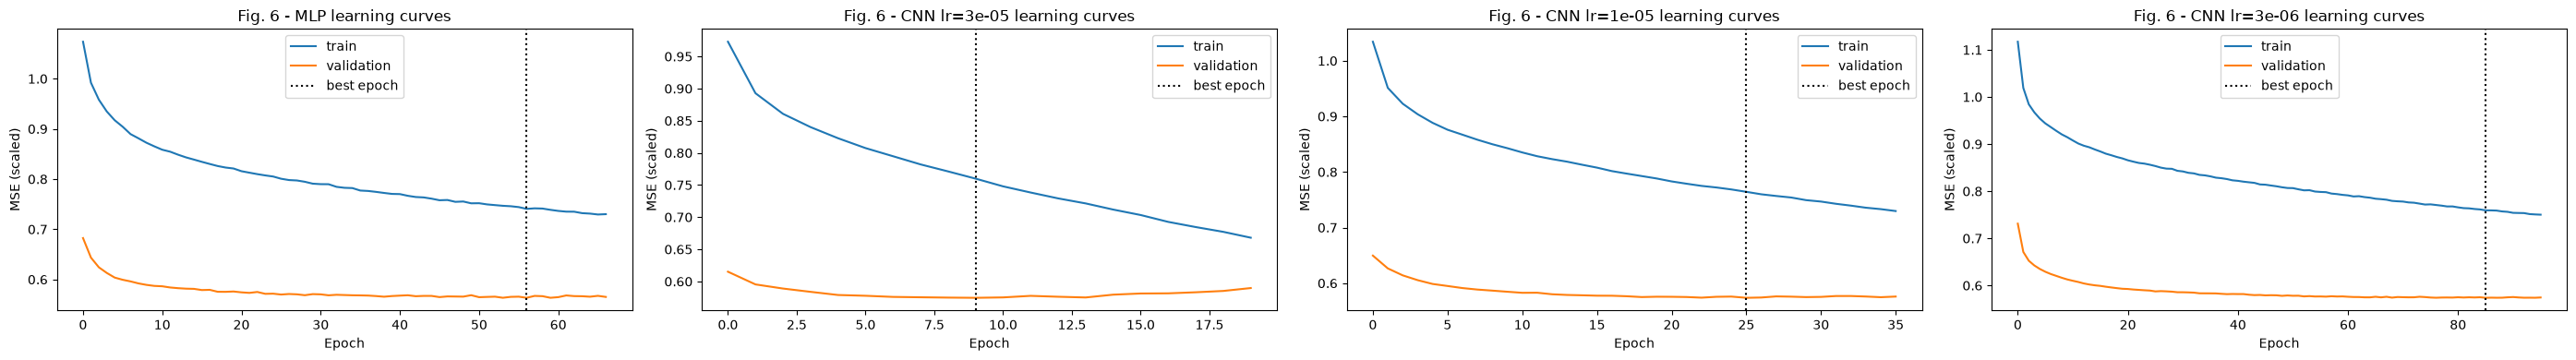

,val MAE,val RMSE,val MAE (all hours),val MAE (daily starts),params,train time (s),seed
Seasonal naive (day),0.584741,0.866905,0.584761,0.584847,0,0.0,-
Seasonal naive (week),0.530974,0.797695,0.521579,0.530573,0,0.0,-
Ridge,0.436782,0.601467,0.436874,0.437333,72600,0.685541,-
Gradient boosting,0.430688,0.599732,0.430000,0.427897,-,17.163684,42
MLP,0.439304,0.607649,0.439216,0.441443,199576.0,58.329685,42.0
CNN,0.444438,0.613011,0.444651,0.445729,91160.0,38.32841,42.0


In [150]:
histories = {}
mlp_cls = MODEL_SPECS['MLP'][0]
mlp, histories['MLP'], mlp_secs = fit(
    mlp_cls, (X_train, y_train), (X_val, y_val), lr=1e-5
)
register_model('MLP', mlp, mlp_secs)
print(f'MLP: {len(histories["MLP"]["val"])} epochs, {mlp_secs:.1f} s')

cnn_cls = MODEL_SPECS['CNN'][0]
cnn_runs, cnn_lr_trials = {}, []
daily_mask = measured['val'] & daily_origin['val'][:, None]
for lr in (3e-5, 1e-5, 3e-6):
    model, history, secs = fit(
        cnn_cls, (X_train, y_train), (X_val, y_val), lr=lr
    )
    histories[f'CNN lr={lr:g}'] = history
    pred = to_kw(predict(model, X_val), 'val')
    metrics = evaluate(Y_kw['val'], pred, daily_mask)
    cnn_runs[lr] = (model, secs)
    cnn_lr_trials.append({
        'learning rate': lr,
        'val MAE (daily starts)': metrics['MAE'],
        'val RMSE (daily starts)': metrics['RMSE'],
        'epochs': len(history['val']),
        'train time (s)': secs,
    })

cnn_lr_results = pd.DataFrame(cnn_lr_trials).sort_values('val MAE (daily starts)')
display(cnn_lr_results.reset_index(drop=True).round({
    'val MAE (daily starts)': 4,
    'val RMSE (daily starts)': 4,
    'train time (s)': 2,
}))
best_cnn_lr = float(cnn_lr_results.iloc[0]['learning rate'])
best_cnn, best_cnn_secs = cnn_runs[best_cnn_lr]
register_model('CNN', best_cnn, best_cnn_secs)
print(f'Selected CNN learning rate: {best_cnn_lr:g}')

fig, axes = plt.subplots(1, len(histories), figsize=(7 * len(histories), 4), squeeze=False)
for ax, (name, hist) in zip(axes[0], histories.items()):
    ax.plot(hist['train'], label='train')
    ax.plot(hist['val'], label='validation')
    ax.axvline(int(np.argmin(hist['val'])), color='k', ls=':', label='best epoch')
    ax.set(xlabel='Epoch', ylabel='MSE (scaled)', title=f'Fig. 6 - {name} learning curves')
    ax.legend()
plt.tight_layout()
plt.show()

val_scores = table('val')
val_scores

**Reading the learning curves:** if the validation loss bottoms out early while the training loss keeps falling, the model is overfitting. Early stopping keeps the weights from the best validation epoch (the dotted line).

## Grid search (validation only)
The model family (MLP or CNN) with the lower validation MAE above is tuned. The untuned runs reach their best validation loss within the first epochs, so the space leans toward regularisation (lower learning rates, more weight decay and dropout, smaller models). The setup is fixed before any results are seen:
* **Objective:** validation MAE (kW, measured hours).
* **Search space** (both families share lr, batch size and weight decay):
  * MLP: hidden {32, 64} × layers {1, 2} × dropout {0.2, 0.5}
  * CNN: filters {16, 32, 64} × kernel {3, 5} × dropout {0.2, 0.5}
  * Training: MLP lr {3e-4, 1e-6}; CNN lr {3e-5, 1e-5, 3e-6}; batch size {128, 256}; weight decay {1e-2, 1e-1}
* **Budget:** 64 (MLP) or 144 (CNN) trials, at most 100 epochs each, early stopping with patience 10, seed 42.

The test set isn't used here. Neural checkpoints are early-stopped on the existing validation windows; family and hyperparameter selection use midnight-origin measured-hour MAE.

In [151]:
import os

family = val_scores.loc[list(MODEL_SPECS), 'val MAE (daily starts)'].idxmin()
cls, grid = MODEL_SPECS[family]
print('Tuning', family)

trials, best = [], {'val MAE': float('inf')}
for values in itertools.product(*grid.values()):
    cfg = dict(zip(grid, values))
    train_cfg = {k: cfg.pop(k) for k in ('lr', 'batch_size', 'weight_decay')}  # passed to fit(), not to the model
    model, hist, secs = fit(lambda: cls(**cfg), (X_train, y_train), (X_val, y_val), **train_cfg)
    daily_mask = measured['val'] & daily_origin['val'][:, None]
    mae = evaluate(Y_kw['val'], to_kw(predict(model, X_val), 'val'), daily_mask)['MAE']
    trials.append({**cfg, **train_cfg, 'val MAE': mae, 'epochs': len(hist['val']), 'train time (s)': secs})
    if mae < best['val MAE']:
        best = {'val MAE': mae, 'model': model, 'cfg': cfg, 'train_cfg': train_cfg, 'secs': secs}

trials = pd.DataFrame(trials)
trials.sort_values('val MAE').reset_index(drop=True)

Tuning MLP


,hidden,layers,dropout,lr,batch_size,weight_decay,val MAE,epochs,train time (s)
0,32,2,0.2,0.000300,128,0.01,0.435948,25,9.061957
1,64,1,0.5,0.000300,128,0.01,0.436228,31,12.086763
2,64,1,0.5,0.000300,256,0.10,0.436583,25,3.902932
3,64,1,0.2,0.000300,128,0.10,0.436594,14,4.959156
4,64,1,0.5,0.000300,256,0.01,0.436839,25,3.800245
...,...,...,...,...,...,...,...,...,...
59,32,1,0.5,0.000001,256,0.01,0.501883,100,14.661652
60,32,2,0.2,0.000001,256,0.10,0.502258,100,20.808068
61,32,2,0.2,0.000001,256,0.01,0.502336,100,23.849063
62,32,2,0.5,0.000001,256,0.10,0.506546,100,19.086162


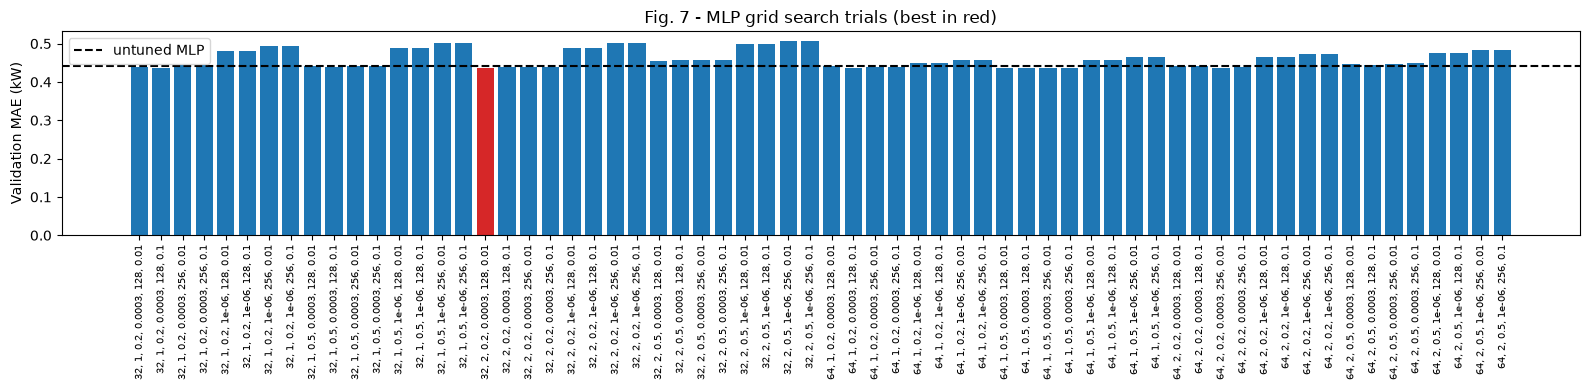

Best config: {'hidden': 32, 'layers': 2, 'dropout': 0.2} | {'lr': 0.0003, 'batch_size': 128, 'weight_decay': 0.01} | val MAE 0.4359 kW -> saved to models/stage1_best.pt


In [152]:
fig, ax = plt.subplots(figsize=(max(12, 0.25 * len(trials)), 4))
labels = trials.drop(columns=['val MAE', 'epochs', 'train time (s)']).astype(str).agg(', '.join, axis=1)
ax.bar(range(len(trials)), trials['val MAE'], color=['C3' if m == best['val MAE'] else 'C0' for m in trials['val MAE']])
ax.axhline(val_scores.loc[family, 'val MAE (daily starts)'], color='k', ls='--', label=f'untuned {family}')
ax.set_xticks(range(len(trials)), labels, rotation=90, fontsize=7)
ax.set(ylabel='Validation MAE (kW)', title=f'Fig. 7 - {family} grid search trials (best in red)')
ax.legend()
plt.tight_layout()
plt.show()

tuned = f'{family} (tuned)'
register_model(tuned, best['model'], best['secs'])

os.makedirs('models', exist_ok=True)
torch.save({'family': family, 'config': best['cfg'], 'train_config': best['train_cfg'], 'state_dict': best['model'].state_dict(),
            'variant': best_variant, 'dropped': best_drop, 'lookback': LOOKBACK, 'horizon': HORIZON, 'target': TARGET, 'features': FEATURES,
            'x_mean': x_scaler.mean_.tolist(), 'x_scale': x_scaler.scale_.tolist()},
           'models/stage1_best.pt')
print('Best config:', best['cfg'], '|', best['train_cfg'], f"| val MAE {best['val MAE']:.4f} kW -> saved to models/stage1_best.pt")

## Final comparison on the untouched test set
The validation-selected models are evaluated once on test data. The main table reports both the existing hourly rolling-origin score and the operational midnight day-ahead score. The month table below uses midnight origins and measured target hours only; it shows whether forecast quality changes across the observed seasons.

Table 2 - Model comparison; primary score is measured-hour MAE on midnight-origin forecasts.
Midnight-origin test scores (measured hours only):


,MAE,RMSE
Seasonal naive (day),0.5318,0.7876
Seasonal naive (week),0.5646,0.8165
Ridge,0.4388,0.5993
Gradient boosting,0.4301,0.5951
MLP,0.4411,0.6016
CNN,0.4438,0.6035
MLP (tuned),0.4354,0.5994


Midnight-origin test errors by target month (measured hours only):


MAE    RMSE
month model                                
Feb   Seasonal naive (day)   0.7201  1.0495
      Seasonal naive (week)  0.6974  1.0044
      Ridge                  0.5243  0.7325
      Gradient boosting      0.5344  0.7279
      MLP                    0.5131  0.7246
...                             ...     ...
Nov   Ridge                  0.4900  0.6836
      Gradient boosting      0.4907  0.6894
      MLP                    0.4947  0.6935
      CNN                    0.5057  0.6927
      MLP (tuned)            0.5095  0.7001

[70 rows x 2 columns]

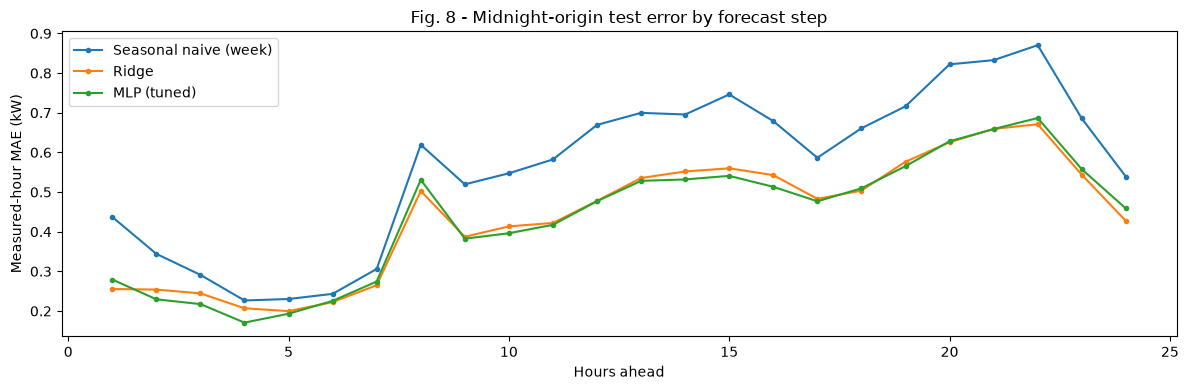

In [153]:
results = table('val', 'test')
reference = results.loc[['Seasonal naive (day)', 'Seasonal naive (week)'], 'val MAE (daily starts)'].idxmin()
results['test improvement vs daily baseline (%)'] = 100 * (
    1 - results['test MAE (daily starts)'] / results.loc[reference, 'test MAE (daily starts)'])
print('Table 2 - Model comparison; primary score is measured-hour MAE on midnight-origin forecasts.')
results.round(4)

t_test = data['test'][2]
daily_test = daily_origin['test']
daily_t = t_test[daily_test]
target_rows = daily_t[:, None] + np.arange(HORIZON)
actual = gap[target_rows]
observed = ~imputed.to_numpy()[target_rows]
test_predictions = {name: prediction(name, 'test')[daily_test] for name in predictors}

daily_scores = pd.DataFrame({name: evaluate(actual, forecast, observed)
                             for name, forecast in test_predictions.items()}).T
print('Midnight-origin test scores (measured hours only):')
display(daily_scores.round(4))

target_month = features.index.month.to_numpy()[target_rows]
monthly_rows = []
for month in np.unique(target_month):
    month_mask = observed & (target_month == month)
    for name, forecast in test_predictions.items():
        if month_mask.any():
            monthly_rows.append({'month': pd.Timestamp(2010, int(month), 1).strftime('%b'),
                                 'model': name, **evaluate(actual, forecast, month_mask)})
monthly_test_scores = pd.DataFrame(monthly_rows).set_index(['month', 'model'])
print('Midnight-origin test errors by target month (measured hours only):')
display(monthly_test_scores.round(4))

fig, ax = plt.subplots(figsize=(12, 4))
for name in [reference, 'Ridge', tuned]:
    forecast = test_predictions[name]
    step_error = np.where(observed, np.abs(forecast - actual), np.nan)
    ax.plot(np.arange(1, HORIZON + 1), np.nanmean(step_error, axis=0), marker='.', label=name)
ax.set(xlabel='Hours ahead', ylabel='Measured-hour MAE (kW)',
       title='Fig. 8 - Midnight-origin test error by forecast step')
ax.legend()
plt.tight_layout()
plt.show()

## Conclusion and next risk
Use the tables above to compare models on the same untouched test period. Focus on the measured-hour **daily-start** MAE, then check whether the monthly table shows a seasonal weakness. The annual effects are still provisional: the training period contains only about 2.4 years and the test period covers February to November 2010, not a complete year.

**Unresolved risks:** forecast windows overlap for the hourly rolling score, and the final test period is less than a full year. A later evaluation should use additional years or rolling-origin folds spanning complete seasons. Inputs and seasonal baselines are causal and fit from past/training rows only; imputed target hours are excluded from primary MAE/RMSE.

## Smoke test
A quick end-to-end check for the TA, which takes seconds and doesn't need the grid search to be re-run:
1. Reload the saved checkpoint and predict with it.
2. Train the same architecture for one epoch on 2,000 windows.

In [154]:
ckpt = torch.load('models/stage1_best.pt', map_location=device)
smoke_cls = MODEL_SPECS[ckpt['family']][0]

reloaded = smoke_cls(**ckpt['config']).to(device)
reloaded.load_state_dict(ckpt['state_dict'])

X_s, y_s = X_train[:2000], y_train[:2000]
smoke_model, _, _ = fit(lambda: smoke_cls(**ckpt['config']), (X_s, y_s), (X_s[:200], y_s[:200]),
                        max_epochs=1, **ckpt['train_config'])

for out in (predict(reloaded, X_val[:200]), predict(smoke_model, X_val[:200])):
    assert out.shape == (200, HORIZON) and np.isfinite(out).all()
print('Smoke test passed on', device, '| output shape', out.shape)

Smoke test passed on cuda | output shape (200, 24)
